Name: Sana Raza

Labpartner(s)

In [1]:
#import statements go here
import pandas as pd
import matplotlib.pyplot as plt

# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [2]:
df = pd.read_csv('player_stats.csv')
played = df[df['minutes_played'] > 0].copy()

role
Starter    141
Sub         32
Name: count, dtype: int64
role
Starter    0.286217
Sub        0.415965
Name: goals_per_90, dtype: float64


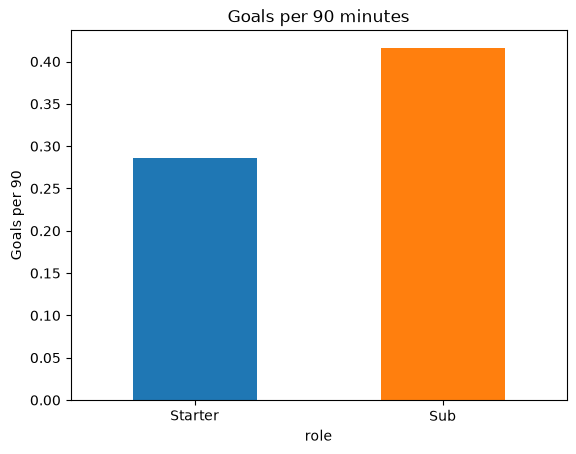

In [3]:
# A forward (shown as FWD in the World Cup data) is the attacking player in football (soccer). 
# Their main job is to score goals. 
# They play closest to the other team's goal and are often called strikers.

fwd = played[(played['position'] == 'FWD') & (played['minutes_played'] >= 90)].copy()
fwd['goals_per_90'] = fwd['goals'] / fwd['minutes_played'] * 90

fwd['role'] = 'Starter'
fwd.loc[fwd['matches_started'] < fwd['matches_played'] / 2, 'role'] = 'Sub'

print(fwd['role'].value_counts())
print(fwd.groupby('role')['goals_per_90'].mean())

fwd.groupby('role')['goals_per_90'].mean().plot(kind='bar', color=['tab:blue', 'tab:orange'])
plt.title('Goals per 90 minutes')
plt.ylabel('Goals per 90')
plt.xticks(rotation=0)
plt.show()

games
3    20.3125
4    21.6250
5    22.7500
6    22.7500
8    23.7500
Name: players_used, dtype: float64
Correlation: 0.55


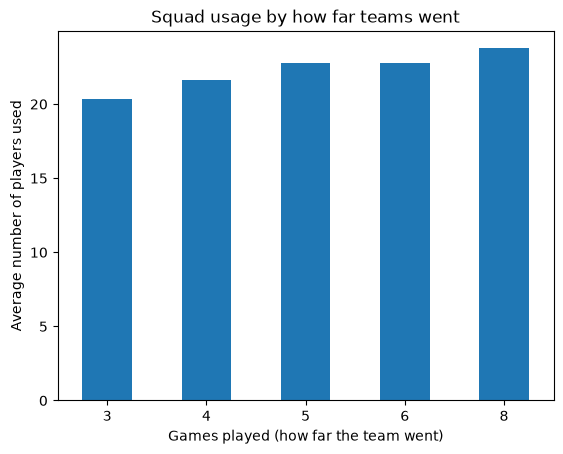

In [4]:
players_used = played.groupby('team_id').size()
games = df.groupby('team_id')['matches_played'].max()

squad = pd.DataFrame({'players_used': players_used, 'games': games})
print(squad.groupby('games')['players_used'].mean())
print('Correlation:', round(squad['players_used'].corr(squad['games']), 2))

squad.groupby('games')['players_used'].mean().plot(kind='bar', rot=0)
plt.xlabel('Games played (how far the team went)')
plt.ylabel('Average number of players used')
plt.title('Squad usage by how far teams went')
plt.show()

Among the forwards with more than 90 minutes, the substitutes scored more goals per 90 minutes (0.42) than starters (0.29). However, there were only 32 subs vs 141 starters.Teams that went further used more players. But this is partly built-in, because the teams that play more games have more chances to use extra players. 

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

In [5]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pk = pd.read_csv('parkinsons_data.csv')
print(pk.shape)
pk.head()

(1199, 20)


,Genetic locus,Polymorphism,Location (hg18),Allele contrast,Ethnicity,N studies,N samples,OR (95% CI),P-value,Amount,N minor,Replication,I2,Bias,Bias reason,Overall Grade,logBF,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,NTNG1,rs11185076,chr1:107598223,A vs. T,All (C only),4,"3,925",1.09 (0.94-1.26),0.2580,-,-,-,-,-,-,-,-,NaN,NaN,NaN
1,GNAI3,rs6692804,chr1:109910265,A vs. G,C,4,"3,966",0.94 (0.71-1.23),0.6270,-,-,-,-,-,-,-,-,NaN,NaN,"GBA', 'ATP13A2', 'LRRK2', 'SNCA', 'PINK1', 'PR..."
2,GNAI3,rs6692804,chr1:109910265,A vs. G,"All (C, A)",5,"4,744",0.96 (0.78-1.18),0.7010,-,-,-,-,-,-,-,-,NaN,NaN,"DNAJC13', 'TMEM230', 'SYT11/RAB25', 'CASP9', '..."
3,GSTM1,GSTM1*0,chr1:110034444,ins vs. del,C,12,"6,150",0.90 (0.83-0.98),0.0153,A,"3,465",A,0,C,Low OR,C,<1,NaN,NaN,NaN
4,GSTM1,GSTM1*0,chr1:110034444,ins vs. del,"All (C, A, O)",15,"7,897",0.92 (0.84-1.01),0.0750,-,-,-,-,-,-,-,-,NaN,NaN,NaN


In [7]:
# The last 3 columns are empty / junk, so remove them
pk = pk.drop(columns=['Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19'])

# '-' means missing, so turn it into a real missing value (NaN)
pk = pk.replace('-', np.nan)

# '3,925' is text. Remove the comma and turn it into a number
pk['N samples'] = pk['N samples'].str.replace(',', '').astype(int)

# 'OR (95% CI)' looks like '1.09 (0.94-1.26)'. A regular expression pulls out the 3 numbers.
# ([\d.]+) means "a group of digits and dots" and each ( ) group becomes one column
parts = pk['OR (95% CI)'].str.extract(r'([\d.]+) \(([\d.]+)-([\d.]+)\)')
pk['OR'] = parts[0].astype(float)
pk['CI_low'] = parts[1].astype(float)
pk['CI_high'] = parts[2].astype(float)

# 'chr1:107598223' -> chromosome 1, position 107598223. The X chromosome becomes 23 so it can be a number
loc = pk['Location (hg18)'].str.extract(r'chr(\w+):(\d+)')
pk['chromosome'] = loc[0].replace('X', '23').astype(int)
pk['position'] = loc[1].astype(int)

pk[['Genetic locus', 'OR (95% CI)', 'OR', 'CI_low', 'CI_high', 'chromosome', 'position']].head()

,Genetic locus,OR (95% CI),OR,CI_low,CI_high,chromosome,position
0,NTNG1,1.09 (0.94-1.26),1.09,0.94,1.26,1,107598223
1,GNAI3,0.94 (0.71-1.23),0.94,0.71,1.23,1,109910265
2,GNAI3,0.96 (0.78-1.18),0.96,0.78,1.18,1,109910265
3,GSTM1,0.90 (0.83-0.98),0.90,0.83,0.98,1,110034444
4,GSTM1,0.92 (0.84-1.01),0.92,0.84,1.01,1,110034444


In [8]:
# -log10(p) turns tiny p-values into big numbers: p = 0.001 -> 3, p = 1e-20 -> 20
pk['neg_log10_p'] = -np.log10(pk['P-value'])

# Genetics uses a very strict cutoff because thousands of variants are tested
pk['significant'] = pk['P-value'] < 5e-8

# Some variants appear more than once (different ethnic groups).
# Keep only the row with the most samples for each variant.
best = pk.sort_values('N samples', ascending=False).drop_duplicates('Polymorphism')
best = best.sort_values(['chromosome', 'position'])

print('Rows:', len(pk), '| Unique variants:', len(best), '| Significant:', best['significant'].sum())

best[best['significant']].sort_values('P-value')[['Genetic locus', 'Polymorphism', 'chromosome', 'N samples', 'OR', 'P-value']].head(10)

Rows: 1199 | Unique variants: 887 | Significant: 101


,Genetic locus,Polymorphism,chromosome,N samples,OR,P-value
402,SNCA,rs356219*,4,81774,1.30,2.510000e-66
1127,MAPT/STH,H1H2,17,51707,0.78,2.710000e-49
405,SNCA,rs11931074,4,58088,1.38,2.520000e-47
1044,MAPT/STH,rs2942168*,17,45647,0.78,2.270000e-46
424,SNCA,rs2736990,4,24887,1.26,1.770000e-34
408,SNCA,rs356220,4,20427,1.31,1.110000e-33
421,SNCA,rs3857059,4,40787,1.41,2.860000e-32
1070,IMP5,rs12373139,17,27442,0.78,8.250000e-27
1135,MAPT/STH,rs199533,17,24515,0.77,8.850000e-26
1067,IMP5,rs12185268,17,22814,0.77,5.530000e-25


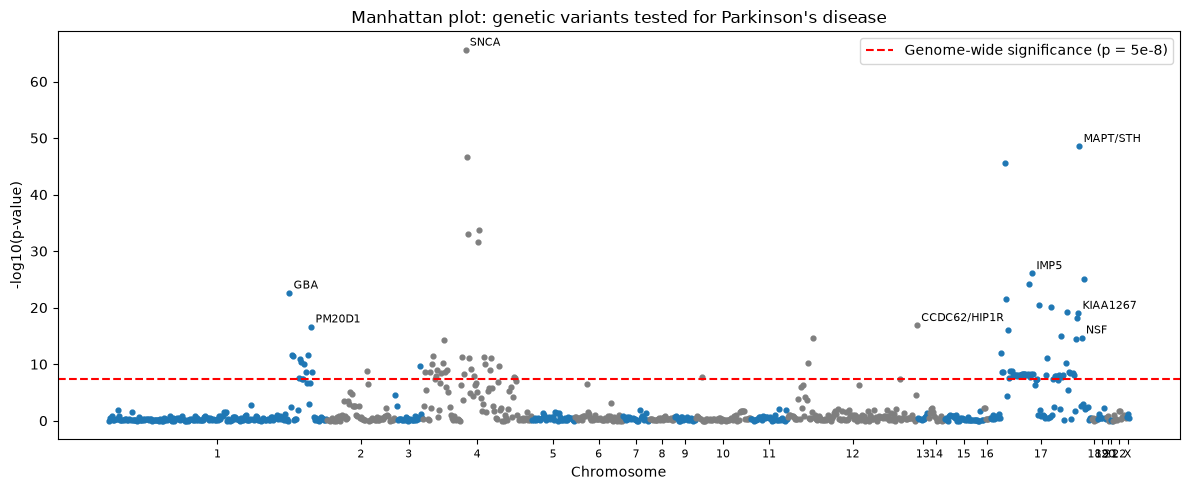

In [9]:
# Manhattan plot: every dot is a variant, ordered along the chromosomes.
best['x'] = range(len(best))

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['tab:blue', 'tab:gray']
for i, (chrom, group) in enumerate(best.groupby('chromosome')):
    ax.scatter(group['x'], group['neg_log10_p'], color=colors[i % 2], s=12)   # alternate colors per chromosome

ax.axhline(-np.log10(5e-8), color='red', linestyle='--', label='Genome-wide significance (p = 5e-8)')

# Put the chromosome number under the middle of each chromosome
ticks = best.groupby('chromosome')['x'].median()
ax.set_xticks(ticks.values)
ax.set_xticklabels([str(c) if c != 23 else 'X' for c in ticks.index], fontsize=8)

# Label the 8 strongest genes
top = best.sort_values('P-value').drop_duplicates('Genetic locus').head(8)
for _, row in top.iterrows():
    ax.annotate(row['Genetic locus'], (row['x'], row['neg_log10_p']), fontsize=8,
                xytext=(3, 3), textcoords='offset points')

ax.set_xlabel('Chromosome')
ax.set_ylabel('-log10(p-value)')
ax.set_title("Manhattan plot: genetic variants tested for Parkinson's disease")
ax.legend()
plt.tight_layout()
plt.show()

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

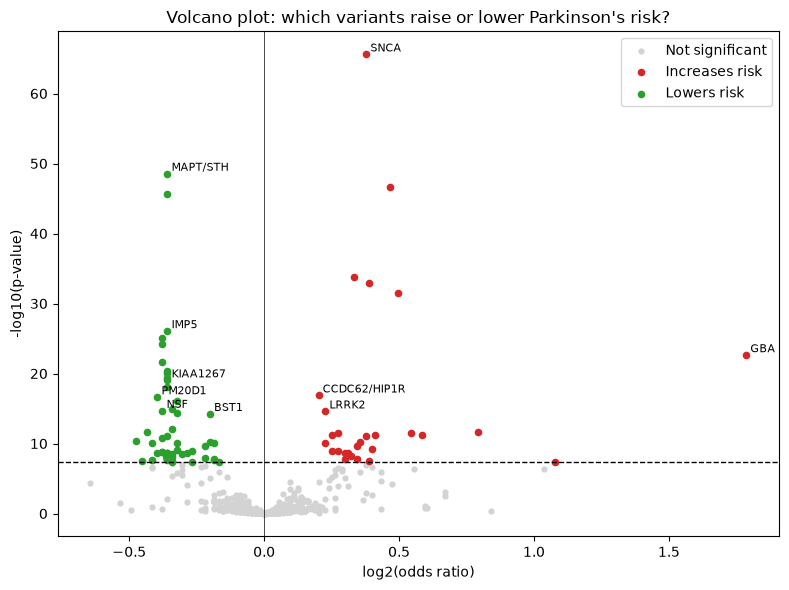

Significant risk variants: 28
Significant protective variants: 73


In [10]:
# Volcano plot: x = effect size, y = how significant.
# Right side = increases risk, left side = lowers risk (protective).
# log2(OR): 0 means no effect, +1 means double the odds, -1 means half the odds
best['log2_OR'] = np.log2(best['OR'])

risk = best['significant'] & (best['OR'] > 1)
protective = best['significant'] & (best['OR'] < 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(best.loc[~best['significant'], 'log2_OR'], best.loc[~best['significant'], 'neg_log10_p'],
           color='lightgray', s=12, label='Not significant')
ax.scatter(best.loc[risk, 'log2_OR'], best.loc[risk, 'neg_log10_p'], color='tab:red', s=20, label='Increases risk')
ax.scatter(best.loc[protective, 'log2_OR'], best.loc[protective, 'neg_log10_p'], color='tab:green', s=20, label='Lowers risk')

ax.axhline(-np.log10(5e-8), color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linewidth=0.5)

# Label the strongest variant of the 10 most significant genes
labels = best[best['significant']].sort_values('P-value').drop_duplicates('Genetic locus').head(10)
for _, row in labels.iterrows():
    ax.annotate(row['Genetic locus'], (row['log2_OR'], row['neg_log10_p']), fontsize=8,
                xytext=(3, 2), textcoords='offset points')

ax.set_xlabel('log2(odds ratio)')
ax.set_ylabel('-log10(p-value)')
ax.set_title("Volcano plot: which variants raise or lower Parkinson's risk?")
ax.legend()
plt.tight_layout()
plt.show()

print('Significant risk variants:', risk.sum())
print('Significant protective variants:', protective.sum())

## My findings?

1. The file has like 1199 rows with only 887 unique variants.
2. 101 variants in 22 genes** pass the strict genetics cutoff (p < 5e-8).
3. The Manhattan plot shows a big tower on chromosome 17 made of many genes like (MAPT, CRHR1, IMP5, KIAA1267, NSF). They are most likely one region of DNA that is inherited together, not 5 separate efforts
4. Volcano plot shows that 28 significant variants that increases risk (like SNCA, GBA and LRRK2) and 73 that 
lower it (mostly the chromosome 17 region and BST1).

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


**Answer:** My use of AI in the above workflow falls under treating AI tool as a junior
assistant. In doing, E.1 and E.2, AI gives me suggestions on how to code different kinds of plots. This is the type of AI use that Wiley encourages to use. Moreover, the dangers that exists here is this that if I let AI do all the work without checking the accuracy, then it is bad. In contrast, if I do not take help from AI to polish or even give me better code suggestions, then it is the opportunity that I am missing.


To give a clear example. When I was debugging my code, AI was saying to me that the last three columns that I have in my datasets were 'empty or junk'. However, the column Unnamed: 19 actually contained lists of gene names. AI also mentioned the labeled variants as risk or protective without checking the Allele contrast column which is incorrect. This also shows why Wiley mentions that the authors must verify AI output.

**When is the AI use ethical in research?**

Based on the guides, AI is ethical to be used for generating the standard code, polishing language as well as organizing data along with exploring the patterns. But if you are asking it to create the citations, then every citation should be checked against a real source and the use should be disclosed as well. Like Wiley mentioned that unpublished findings and novel methods should not be uploaded as well. 

**When is it in my interest as a student and when is not?**

As per the guide, Wiley warns against using AI to by pass the skill-building step. Moreover, if I let AI handle the statistics as well as the interpretation in my research, I would lose the understanding I am supposed to be developing.

**What are the enviornmental considerations of using AI?**

The environmental considerations of using AI depends on how you use it. If for instance, you are using an already trained model, then your environmental impact would depend on the size of model, how much you are using it etc along with the complexity of the requests.
The impact is also more when you need complex tasks to be done but then it requires more computation which in turns means higher environmental impact. Worst of all, if you are training the model from scratch, then this is  the most resource-intensive use of AI, and responsible for AI's reported carbon footprint. 

**How might you use AI in your final project in line with ethical guidelines? You should be writing a few paragraphs at minimum with examples here.**

Wiley mentioned that the answers coming out of AI should be thoughtfully judged. Hence, I would be using AI sometimes to debug my code. But at the end, the answer that comes out of it should be accepted as a 
'correct' answer only after I judge it. Moreover, I have an idea of what methods I would be using and the expected results that I should get. However,  I might use AI for enhancing or beautifying my plots. Additionally, I would keep a short log book that will have all the AI tools and versions that I used.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

## Cheat sheet
These are the cleaning and plotting tricks I used in E.1 and E.2. The examples use a small made-up table, so they run on their own.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

genes = pd.DataFrame({
    'gene': ['SNCA', 'MAPT', 'LRRK2', 'GBA', 'BST1'],
    'location': ['chr4:90856624', 'chr17:41281077', 'chr12:39020469', 'chr1:153471451', 'chrX:15620117'],
    'samples': ['81,774', '51,707', '-', '12,410', '9,050'],
    'or_ci': ['1.30 (1.26-1.35)', '0.78 (0.75-0.81)', '1.15 (1.09-1.21)', '3.51 (2.89-4.26)', '0.88 (0.84-0.92)'],
    'p': [2.5e-66, 2.7e-49, 1.0e-10, 3.0e-30, 4.0e-9],
})
print(genes)

    gene        location samples             or_ci             p
0   SNCA   chr4:90856624  81,774  1.30 (1.26-1.35)  2.500000e-66
1   MAPT  chr17:41281077  51,707  0.78 (0.75-0.81)  2.700000e-49
2  LRRK2  chr12:39020469       -  1.15 (1.09-1.21)  1.000000e-10
3    GBA  chr1:153471451  12,410  3.51 (2.89-4.26)  3.000000e-30
4   BST1   chrX:15620117   9,050  0.88 (0.84-0.92)  4.000000e-09


In [12]:
# 1. replace(): turn '-' into a real missing value (NaN) so pandas knows it is empty
genes = genes.replace('-', np.nan)

# 2. .str.replace() + astype(): '81,774' is text, so remove the comma and make it a number
# I used float, not int, because int cannot hold NaN (the missing LRRK2 value would cause an error)
genes['samples'] = genes['samples'].str.replace(',', '').astype(float)
print(genes['samples'])

0    81774.0
1    51707.0
2        NaN
3    12410.0
4     9050.0
Name: samples, dtype: float64


In [13]:
# 3. .str.extract(): each ( ) group in the pattern becomes its own column
# [\d.]+  means "one or more digits or dots", so it matches numbers like 1.30
# \(  means a real "(" character (the backslash stops it being a group)
parts = genes['or_ci'].str.extract(r'([\d.]+) \(([\d.]+)-([\d.]+)\)')
print(parts)                       # 3 columns: 0, 1, 2

genes['OR'] = parts[0].astype(float)
genes['CI_low'] = parts[1].astype(float)
genes['CI_high'] = parts[2].astype(float)

# Same idea for 'chr4:90856624' -> chromosome 4, position 90856624
# \w+ means letters or digits (so it also matches X); \d+ means digits only
loc = genes['location'].str.extract(r'chr(\w+):(\d+)')
genes['chromosome'] = loc[0].replace('X', '23').astype(int)   # X becomes 23 so it can be a number
genes['position'] = loc[1].astype(int)

print(genes[['gene', 'OR', 'CI_low', 'CI_high', 'chromosome', 'position']])

      0     1     2
0  1.30  1.26  1.35
1  0.78  0.75  0.81
2  1.15  1.09  1.21
3  3.51  2.89  4.26
4  0.88  0.84  0.92
    gene    OR  CI_low  CI_high  chromosome   position
0   SNCA  1.30    1.26     1.35           4   90856624
1   MAPT  0.78    0.75     0.81          17   41281077
2  LRRK2  1.15    1.09     1.21          12   39020469
3    GBA  3.51    2.89     4.26           1  153471451
4   BST1  0.88    0.84     0.92          23   15620117


In [14]:
# 4. -log10(p): turns tiny p-values into big numbers, easier to plot
#    p = 0.001 -> 3,   p = 1e-20 -> 20
genes['neg_log10_p'] = -np.log10(genes['p'])

# log2(OR): makes odds ratios symmetric around 0
#    OR = 1 -> 0 (no effect),  OR = 2 -> +1 (double),  OR = 0.5 -> -1 (half)
genes['log2_OR'] = np.log2(genes['OR'])

print(genes[['gene', 'p', 'neg_log10_p', 'OR', 'log2_OR']])

    gene             p  neg_log10_p    OR   log2_OR
0   SNCA  2.500000e-66    65.602060  1.30  0.378512
1   MAPT  2.700000e-49    48.568636  0.78 -0.358454
2  LRRK2  1.000000e-10    10.000000  1.15  0.201634
3    GBA  3.000000e-30    29.522879  3.51  1.811471
4   BST1  4.000000e-09     8.397940  0.88 -0.184425


In [15]:
# 5. Keep only the biggest row for each variant:
#    sort biggest first, then drop_duplicates() keeps the FIRST row it sees
dups = pd.DataFrame({
       'variant': ['rs1', 'rs1', 'rs2', 'rs2', 'rs3'],
       'group':   ['Asian', 'All', 'European', 'All', 'All'],
       'samples': [3000, 9000, 4000, 7000, 5000],
})
best = dups.sort_values('samples', ascending=False).drop_duplicates('variant')
print(best)

# 6. Boolean masks: & means "and", and each condition needs its own ( )
significant = genes['p'] < 5e-8
risk = significant & (genes['OR'] > 1)
protective = significant & (genes['OR'] < 1)
print('Risk:', genes.loc[risk, 'gene'].tolist())
print('Protective:', genes.loc[protective, 'gene'].tolist())
print('Number of risk genes:', risk.sum())   # True counts as 1, so sum() counts them

  variant group  samples
1     rs1   All     9000
3     rs2   All     7000
4     rs3   All     5000
Risk: ['SNCA', 'LRRK2', 'GBA']
Protective: ['MAPT', 'BST1']
Number of risk genes: 3


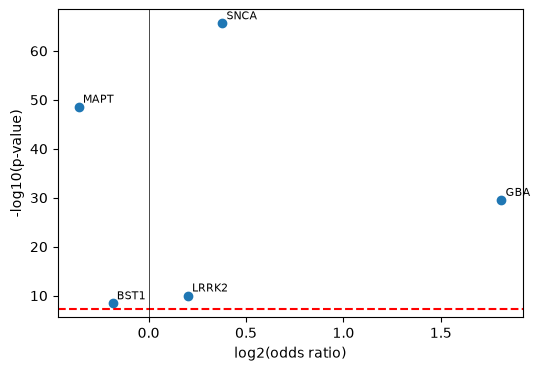

0 1 ['GBA']
1 4 ['SNCA']
2 12 ['LRRK2']
3 17 ['MAPT']
4 23 ['BST1']


In [16]:
# 7.  Reference lines and point labels
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(genes['log2_OR'], genes['neg_log10_p'])

ax.axhline(-np.log10(5e-8), color='red', linestyle='--')   # horizontal line (significance cutoff)
ax.axvline(0, color='black', linewidth=0.5)                # vertical line at "no effect"

# annotate(): write text next to a point
# xytext=(3, 3) with textcoords='offset points' moves the label 3 points right and up
for _, row in genes.iterrows():
    ax.annotate(row['gene'], (row['log2_OR'], row['neg_log10_p']),
                xytext=(3, 3), textcoords='offset points', fontsize=8)

ax.set_xlabel('log2(odds ratio)')
ax.set_ylabel('-log10(p-value)')
plt.show()

# 8. enumerate() + groupby(): loop over groups and also get a counter i
#    I used i % 2 in the Manhattan plot to alternate colors (0, 1, 0, 1...)
for i, (chrom, group) in enumerate(genes.groupby('chromosome')):
    print(i, chrom, group['gene'].tolist())